## The Data

We will be working with a famous titanic data set for these exercises. Later on in the Machine Learning section of the course, we will revisit this data, and use it to predict survival rates of passengers. For now, we'll just focus on the visualization of the data with seaborn:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
sns.set_style('whitegrid')

In [3]:
df = sns.load_dataset('titanic')

## Show head of data

In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## check null value

In [5]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

# Exercises

## 1. What is the distribution of passengers’ ages?

In [ ]:
# plot here


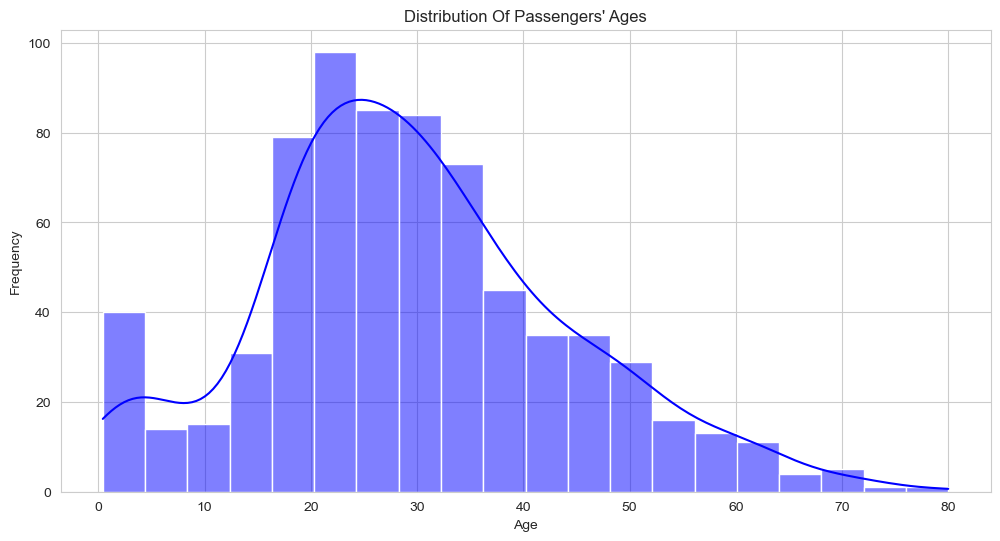

In [32]:
plt.figure(figsize = (12 ,6))
sns.histplot(df["age"] , color = "b" , bins = 20 , kde = True)

plt.title("Distribution Of Passengers' Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

## 2. What is the distribution of passengers’ ages and fare ?
each figure in subplot

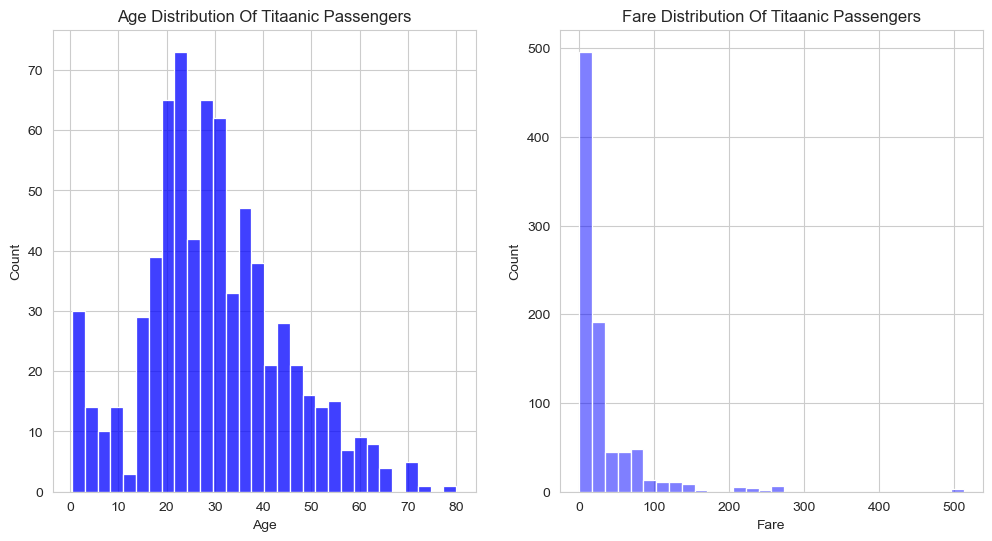

In [31]:
plt.figure(figsize = (12 ,6))
plt.subplot(1,2,1)
sns.histplot(df["age"] , color = "b" , bins = 30)
plt.title("Age Distribution Of Titaanic Passengers")
plt.xlabel("Age")
plt.ylabel("Count")

plt.subplot(1,2,2)

sns.histplot(df["fare"] , color = "b", alpha = .5 , bins = 30)
plt.title("Fare Distribution Of Titaanic Passengers")
plt.xlabel("Fare")
plt.ylabel("Count")
plt.show()

## 3. What is the relationship between age and fare?

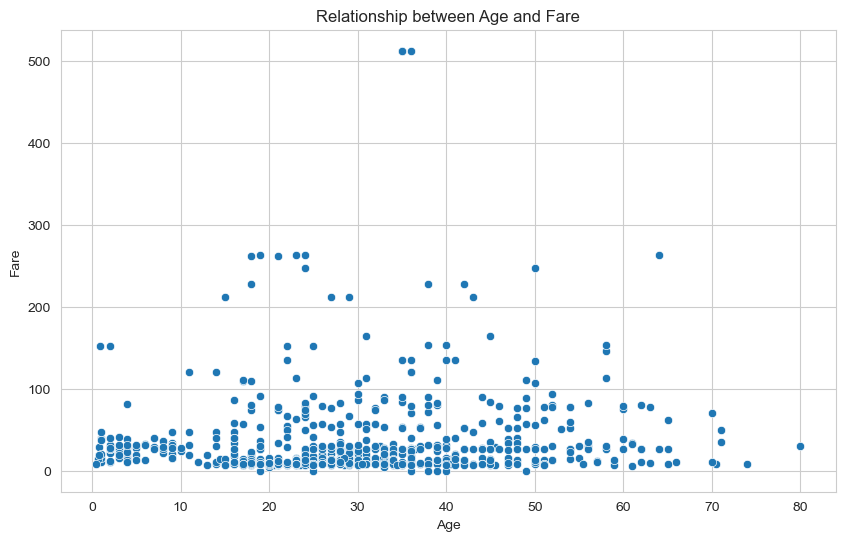

In [44]:
plt.figure(figsize = (10,6))
sns.scatterplot(x= df["age"] , y = df["fare"])
plt.title("Relationship between Age and Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

## 4. What is the relationship between survived and age?

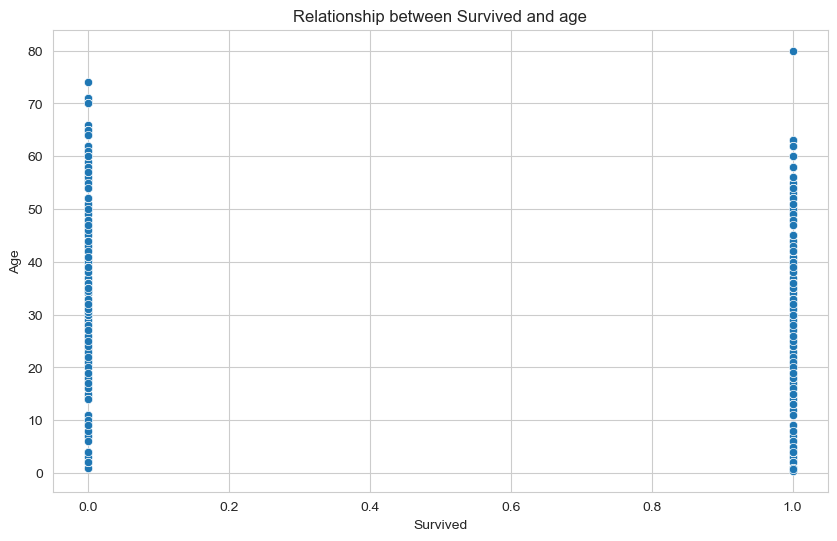

In [45]:
plt.figure(figsize = (10,6))
sns.scatterplot(x= df["survived"] , y = df["age"])
plt.title("Relationship between Survived and age")
plt.xlabel("Survived")
plt.ylabel("Age")
plt.show()

## 5. How does the survival rate vary by gender?

In [60]:
Survived_male = df[df["sex"] == "male"]["survived"].mean()
print(Survived_male)

0.18890814558058924


In [61]:
Survived_female = df[df["sex"] == "female"]["survived"].mean()
print(Survived)

0.7420382165605095


C:\Users\MS\AppData\Local\Temp\ipykernel_19156\2962243690.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data= df , x = "sex" , y = "survived" , palette=["steelblue", "darkorange"])


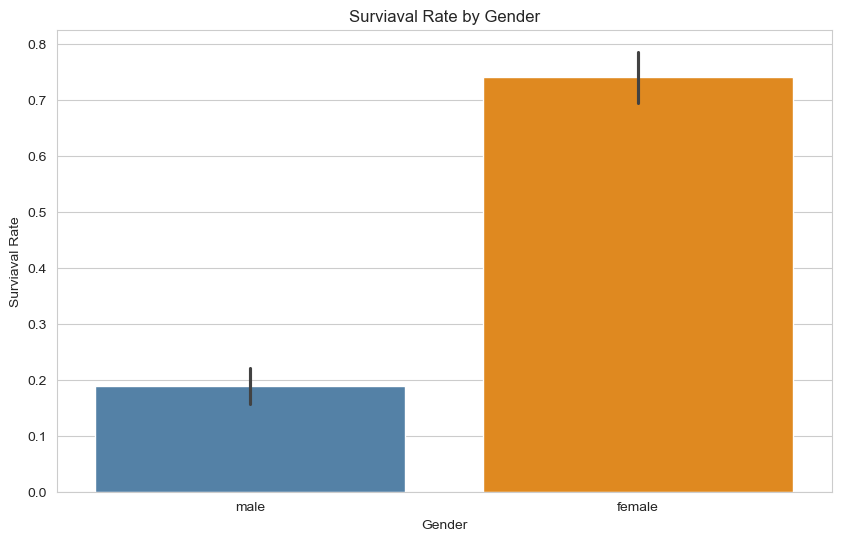

In [66]:
plt.figure(figsize = (10,6))

sns.barplot(data= df , x = "sex" , y = "survived" , palette=["steelblue", "darkorange"])

plt.title("Surviaval Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Surviaval Rate")

plt.show()

## 6. How does the survival rate vary by passenger class?

C:\Users\MS\AppData\Local\Temp\ipykernel_19156\1650018508.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data= df , x = "pclass" , y = "survived" , palette=["blue", "orange" , "green"] , alpha = .6)


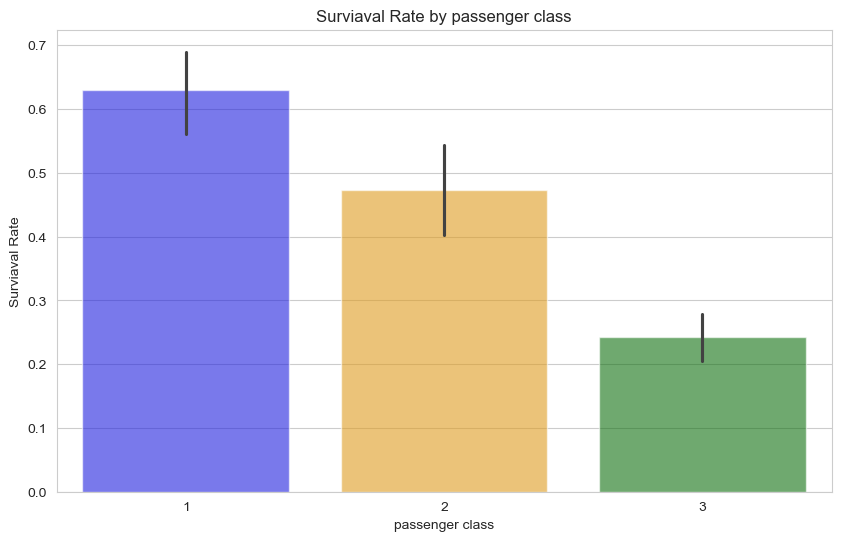

In [69]:
plt.figure(figsize = (10,6))

sns.barplot(data= df , x = "pclass" , y = "survived" , palette=["blue", "orange" , "green"] , alpha = .6)

plt.title("Surviaval Rate by passenger class")
plt.xlabel("passenger class")
plt.ylabel("Surviaval Rate")

plt.show()

## 7. Survival Rate by Age Group

we are dividing the passengers' ages into 5 distinct age groups:
- Ages from 0 to 12 fall into the first bin (typically classified as "Child").
- Ages from 12 to 18 fall into the second bin (classified as "Teen").
- Ages from 18 to 35 fall into the third bin (classified as "Adult").
- Ages from 35 to 60 fall into the fourth bin (classified as "Middle-Aged").
- Ages from 60 to 80 fall into the fifth bin (classified as "Senior").

using pd.cut(data,bins,labels)

In [156]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone', 'Survived_male'],
      dtype='object')

In [167]:
bins = [0, 12, 18, 35, 60 ,80]

labels =  ['Child' , 'Teen' , 'Adult' , 'Middle-Aged' , 'Senior']

df["age_group"] = pd.cut(df["age"] , bins=bins , labels = labels)

df["age_group"].head()

0          Adult
1    Middle-Aged
2          Adult
3          Adult
4          Adult
Name: age_group, dtype: category
Categories (5, object): ['Child' < 'Teen' < 'Adult' < 'Middle-Aged' < 'Senior']

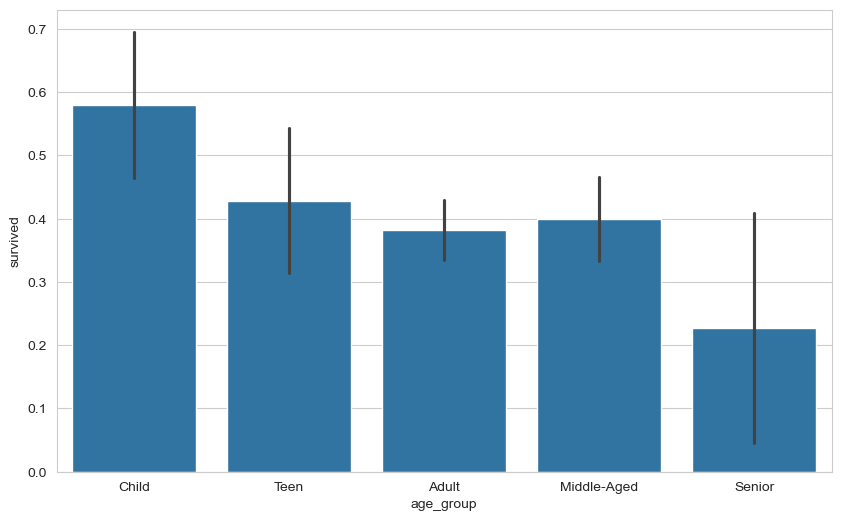

In [178]:
plt.figure(figsize = (10,6))

sns.barplot(data =df , x = df["age_group"] , y = df["survived"] )

plt.show()

## 8. Survival Rate by Embarkation Point for each sex 

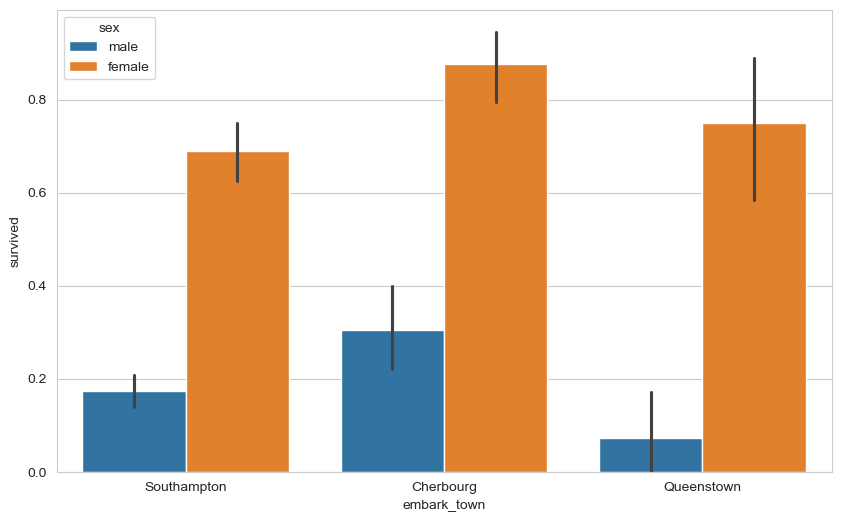

In [179]:
plt.figure(figsize = (10,6))

sns.barplot(data =df , x = df["embark_town"] , y = df["survived"] , hue = "sex" )

plt.show()

## 9. Counting of Passengers by pclass for each sex

In [181]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,Survived_male,age_group
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,0.188908,Adult
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,0.188908,Middle-Aged
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,0.188908,Adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,0.188908,Adult
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,0.188908,Adult


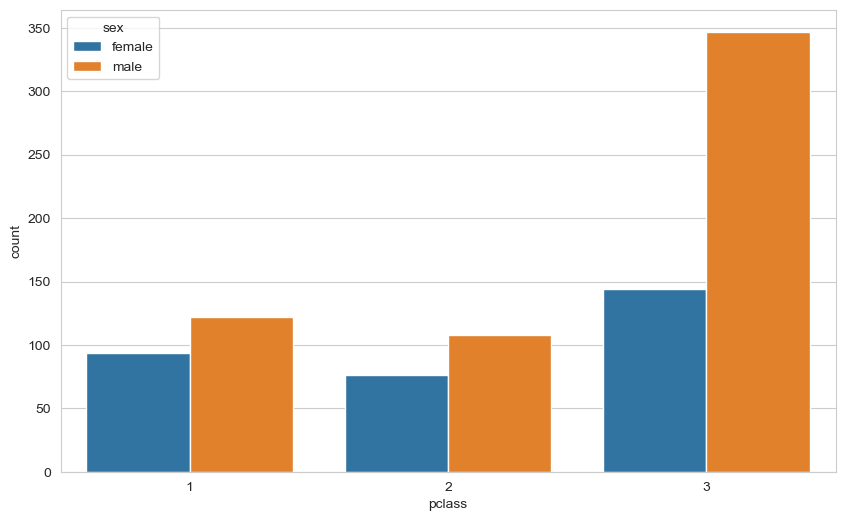

In [199]:
plt.figure(figsize = (10,6))

sns.countplot(data = df , x = "pclass"  , hue = "sex" )

plt.show()

In [57]:
titanic.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone', 'age_group'],
      dtype='object')

## 10. Counting of Passengers by class for each who

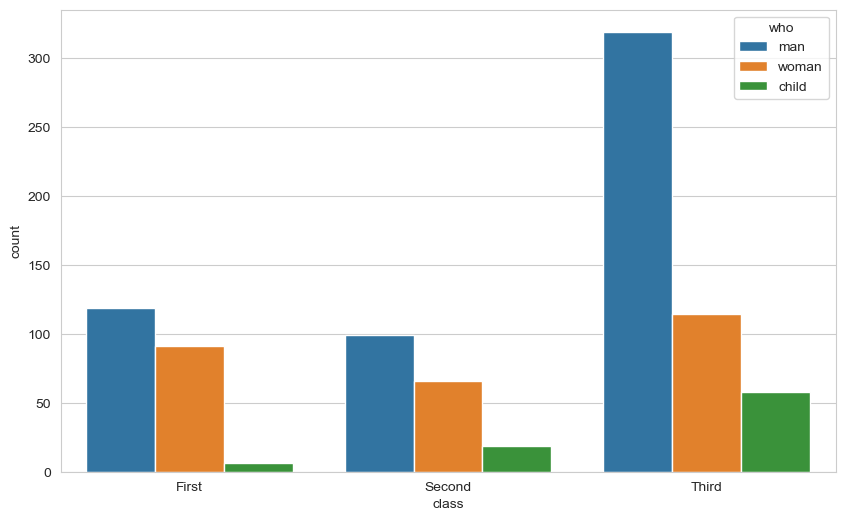

In [205]:
plt.figure(figsize = (10,6))

sns.countplot(data = df , x = "class"  , hue = "who" )

plt.show()

## 11. How many males and females were on board across different classes?

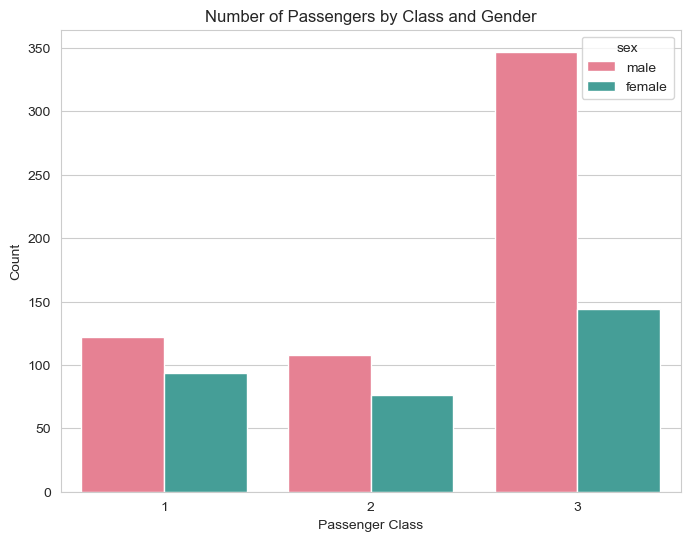

## 12. How does the survival rate vary by embarkation port?

In [138]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone', 'Survived_male'],
      dtype='object')

C:\Users\MS\AppData\Local\Temp\ipykernel_19156\4156942606.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot( x = df["embark_town"] , y = df["survived"] , palette = ["darkblue" , "darkred" , "darkgreen"] , alpha = .8  )


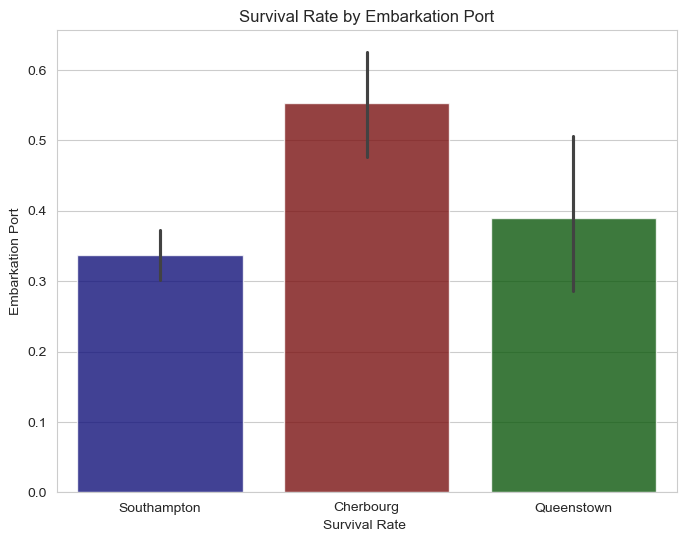

In [155]:
plt.figure(figsize = (8,6))

sns.barplot( x = df["embark_town"] , y = df["survived"] , palette = ["darkblue" , "darkred" , "darkgreen"] , alpha = .8  )

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Survival Rate ")
plt.ylabel("Embarkation Port")
plt.show()

## 13. Correlation Heatmap

In [125]:
data = df.drop(columns = ["adult_male",	"alone",	"Survived_male"])
corr = data.corr(numeric_only = True)
corr

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


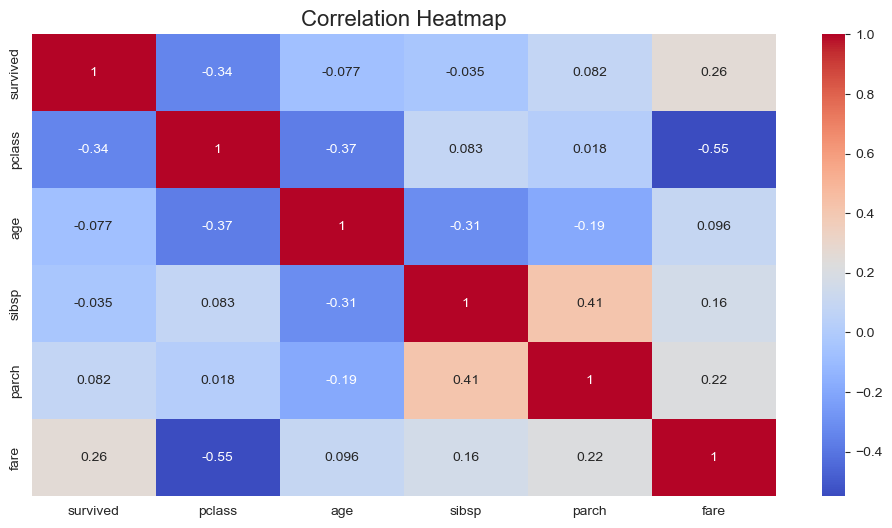

In [132]:
plt.figure(figsize = (12,6))

sns.heatmap(corr , annot= True, fmt="0.2g", cmap="coolwarm")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

## 14. What is the distribution of passengers' fare based on their gender and survival status?
boxplot

In [71]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,Survived_male
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,0.188908
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,0.188908
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,0.188908
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,0.188908
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,0.188908


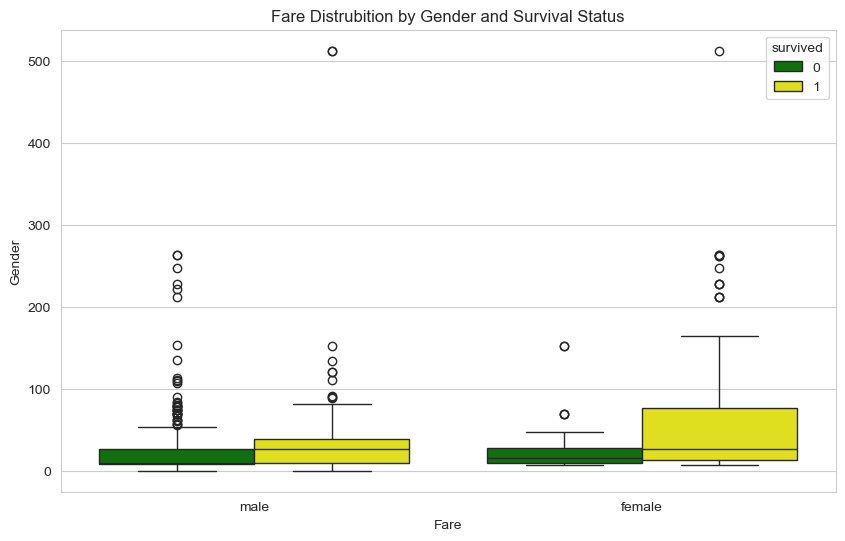

In [85]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df , x = "sex" , y = "fare" , hue = "survived" , palette = ["green" , "yellow"])
plt.title("Fare Distrubition by Gender and Survival Status")
plt.xlabel("Fare")
plt.ylabel("Gender")
plt.show()

## 15. What is the relationship between class, gender, and survival rate?
pointplot()

<Figure size 1000x600 with 0 Axes>

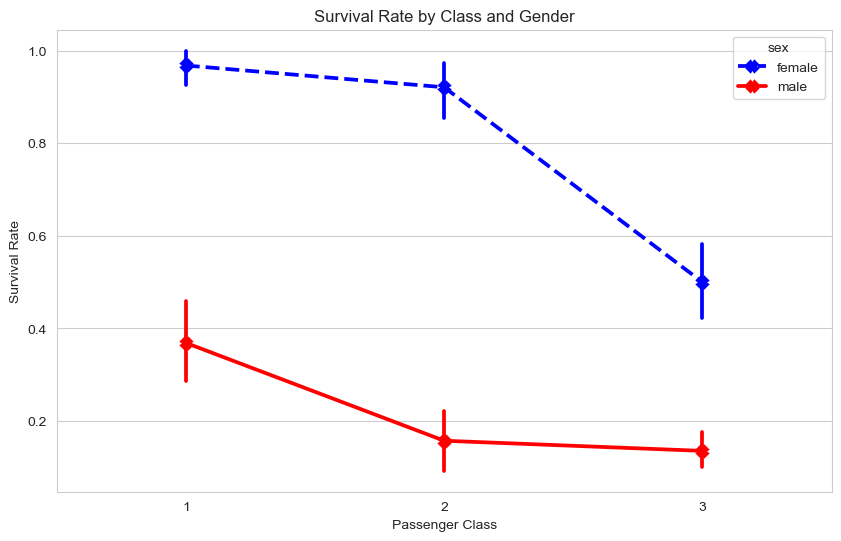

In [116]:
plt.figure(figsize=(10, 6))

sns.pointplot(
    data=df,
    x="pclass",
    y="survived",
    hue="sex",
    markers = "X" ,
        linestyle =[ "--", "-"],
    palette= ["blue" , "red"]
 
)

plt.title("Survival Rate by Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.legend(title="sex")

plt.show()


# Great Job!

### That is it for now! We'll see a lot more of seaborn practice problems in the machine learning section!